# Road Accident Analysis
## Exploratory Data Analysis (EDA)

This notebook explores road accident records to understand accident severity, temporal patterns, road and weather conditions, casualty counts, and geographical distribution.

**Project workflow**
1. Data loading and understanding
2. Data quality assessment
3. Data cleaning and validation
4. Exploratory data analysis
5. Risk segmentation and key observations
6. Interactive dashboard and conclusions

> **Note:** Findings will be based on the dataset. Associations observed in the data should not automatically be interpreted as causes.

## 1. Import Required Libraries

We import the libraries required for data manipulation, numerical calculations, visualization, and file handling.

In [2]:

# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# File and directory handling
import os
from pathlib import Path

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:.2f}".format)

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("All libraries imported successfully!")


All libraries imported successfully!


## 2. Data Loading and Understanding

This section loads the dataset and examines its structure, dimensions, variables, data types, and descriptive statistics.

### 2.1 Load the Dataset

Load the CSV file into a Pandas DataFrame. In Kaggle, attach the dataset through **Add Input**. The code searches the Kaggle input directory and common working locations.

In [3]:

import os
from pathlib import Path

# Locate the dataset file
possible_paths = [
    Path("/kaggle/working/accident_data.csv"),
    Path("/mnt/data/accident_data.csv")
]

# Search Kaggle's attached datasets
kaggle_files = list(Path("/kaggle/input").rglob("accident_data.csv")) \
    if Path("/kaggle/input").exists() else []

DATA_PATH = next(
    (str(path) for path in possible_paths if path.exists()),
    str(kaggle_files[0]) if kaggle_files else None
)

if DATA_PATH is None:
    raise FileNotFoundError(
        "accident_data.csv not found. Please attach the dataset "
        "through Kaggle's Add Input option."
    )

# Load the dataset
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print(f"File path: {DATA_PATH}")


Dataset loaded successfully!
File path: /kaggle/input/datasets/deeplumiere/accident-analysis-dataset/accident_data.csv


### 2.2 Dataset Dimensions

Check the number of records and columns available in the dataset.

In [4]:
# Check the number of rows and columns
rows, columns = df.shape

print(f"Total Records (Rows): {rows:,}")
print(f"Total Features (Columns): {columns}")

Total Records (Rows): 670,679
Total Features (Columns): 14


### 2.3 Preview the Dataset

Display the first five records to understand the structure of individual observations.

In [5]:
df.head()

,Index,Accident_Severity,Accident Date,Latitude,Light_Conditions,District Area,Longitude,Number_of_Casualties,Number_of_Vehicles,Road_Surface_Conditions,Road_Type,Urban_or_Rural_Area,Weather_Conditions,Vehicle_Type
0,200701BS64157,Serious,05-06-2019,51.51,Darkness - lights lit,Kensington and Chelsea,-0.21,1,2,Dry,Single carriageway,Urban,Fine no high winds,Car
1,200701BS65737,Serious,02-07-2019,51.50,Daylight,Kensington and Chelsea,-0.17,1,2,Wet or damp,Single carriageway,Urban,Raining no high winds,Car
2,200701BS66127,Serious,26-08-2019,51.52,Darkness - lighting unknown,Kensington and Chelsea,-0.21,1,3,Dry,NaN,Urban,NaN,Taxi/Private hire car
3,200701BS66128,Serious,16-08-2019,51.50,Daylight,Kensington and Chelsea,-0.20,1,4,Dry,Single carriageway,Urban,Fine no high winds,Bus or coach (17 or more pass seats)
4,200701BS66837,Slight,03-09-2019,51.49,Darkness - lights lit,Kensington and Chelsea,-0.19,1,2,Dry,NaN,Urban,NaN,Other vehicle


### 2.4 Column Names

List all available variables in the dataset.

In [6]:
# Display all column names
df.columns.tolist()

['Index',
 'Accident_Severity',
 'Accident Date',
 'Latitude',
 'Light_Conditions',
 'District Area',
 'Longitude',
 'Number_of_Casualties',
 'Number_of_Vehicles',
 'Road_Surface_Conditions',
 'Road_Type',
 'Urban_or_Rural_Area',
 'Weather_Conditions',
 'Vehicle_Type']

### 2.5 Dataset Information

Review non-null counts, data types, and memory usage.

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 670679 entries, 0 to 670678
Data columns (total 14 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   Index                    670679 non-null  object 
 1   Accident_Severity        670679 non-null  object 
 2   Accident Date            670679 non-null  object 
 3   Latitude                 670654 non-null  float64
 4   Light_Conditions         670679 non-null  object 
 5   District Area            670679 non-null  object 
 6   Longitude                670653 non-null  float64
 7   Number_of_Casualties     670679 non-null  int64  
 8   Number_of_Vehicles       670679 non-null  int64  
 9   Road_Surface_Conditions  669937 non-null  object 
 10  Road_Type                666099 non-null  object 
 11  Urban_or_Rural_Area      670664 non-null  object 
 12  Weather_Conditions       656328 non-null  object 
 13  Vehicle_Type             670679 non-null  object 
dtypes: f

### 2.6 Numerical Descriptive Statistics

Summarize numerical variables using count, mean, standard deviation, quartiles, and range.

In [8]:
df.describe()

,Latitude,Longitude,Number_of_Casualties,Number_of_Vehicles
count,670654.00,670653.00,670679.00,670679.00
mean,52.55,-1.43,1.36,1.83
std,1.41,1.38,0.82,0.72
min,49.91,-7.52,1.00,1.00
25%,51.49,-2.33,1.00,1.00
50%,52.32,-1.41,1.00,2.00
75%,53.45,-0.23,1.00,2.00
max,60.76,1.76,68.00,32.00


### 2.7 Categorical Descriptive Statistics

Review unique values and the most frequent category in text-like columns.

In [9]:
df.describe(include="object")

,Index,Accident_Severity,Accident Date,Light_Conditions,District Area,Road_Surface_Conditions,Road_Type,Urban_or_Rural_Area,Weather_Conditions,Vehicle_Type
count,670679,670679,670679,670679,670679,669937,666099,670664,656328,670679
unique,431020,3,2556,5,422,5,5,3,8,16
top,2.01E+12,Slight,30-11-2019,Daylight,Birmingham,Dry,Single carriageway,Urban,Fine no high winds,Car
freq,239478,572307,704,492201,13701,454593,499607,428038,528789,505502


### 2.8 Unique Values

Count distinct values in each column to understand the variety of categories and identifiers.

In [10]:
df.nunique().sort_values(ascending=False)

Longitude                  538496
Latitude                   519907
Index                      431020
Accident Date                2556
District Area                 422
Number_of_Casualties           36
Number_of_Vehicles             19
Vehicle_Type                   16
Weather_Conditions              8
Light_Conditions                5
Road_Type                       5
Road_Surface_Conditions         5
Accident_Severity               3
Urban_or_Rural_Area             3
dtype: int64

### 2.9 Accident Severity Distribution

Inspect the frequency of each accident severity category as an initial target-variable overview.

In [11]:
df["Accident_Severity"].value_counts(dropna=False)

Accident_Severity
Slight     572307
Serious     89568
Fatal        8804
Name: count, dtype: int64

## 3. Data Quality Assessment

Before cleaning the data, we inspect missing values, duplicate records, numerical ranges, and categorical consistency. These checks help determine which changes, if any, are justified.

### 3.1 Missing Value Analysis

Calculate the number and percentage of missing values in each column. This is an assessment only; no values are filled or removed in this step.

In [12]:

# Calculate missing values and percentages
missing_summary = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df)) * 100
})

# Display columns with missing values first
missing_summary = (
    missing_summary[missing_summary["Missing Values"] > 0]
    .sort_values("Missing Percentage", ascending=False)
)

missing_summary.round(2)


,Missing Values,Missing Percentage
Weather_Conditions,14351,2.14
Road_Type,4580,0.68
Road_Surface_Conditions,742,0.11
Longitude,26,0.00
Latitude,25,0.00
Urban_or_Rural_Area,15,0.00


### 3.2 Visualize Missing Values

Visualize the percentage of missing values in columns where missing data is present.

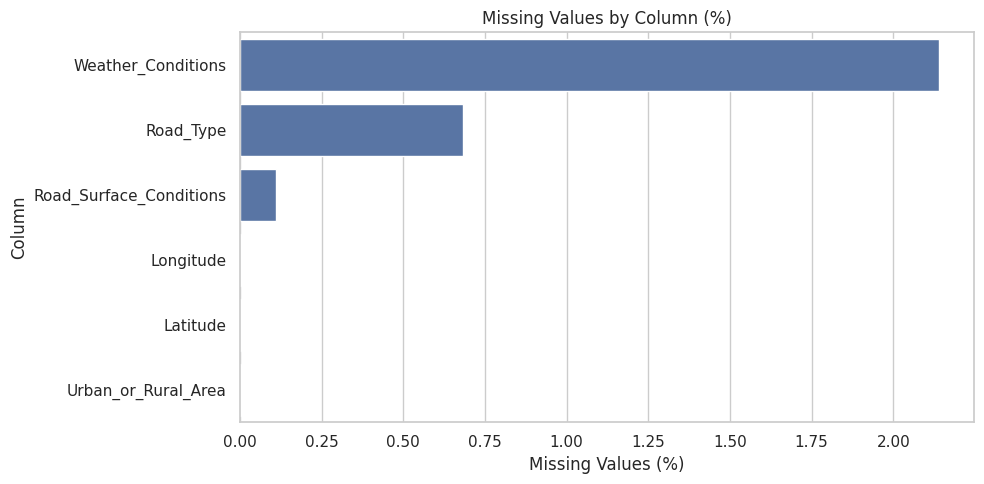

In [13]:

# Plot missing-value percentages
if not missing_summary.empty:
    plt.figure(figsize=(10, 5))

    sns.barplot(
        x=missing_summary["Missing Percentage"],
        y=missing_summary.index
    )

    plt.title("Missing Values by Column (%)")
    plt.xlabel("Missing Values (%)")
    plt.ylabel("Column")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found.")


### 3.3 Exact Duplicate Records

Count rows that are identical across all columns. Duplicate rows should be investigated before removal.

In [14]:
# Count exact duplicate rows
duplicate_count = df.duplicated().sum()

print(f"Total duplicate rows: {duplicate_count:,}")
print(f"Duplicate percentage: {duplicate_count / len(df) * 100:.2f}%")

Total duplicate rows: 19
Duplicate percentage: 0.00%


### 3.4 Consolidated Data Quality Report

Combine missing-value counts, missing percentages, unique-value counts, and data types into one report.

In [15]:

# Create a consolidated data quality report
quality_report = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df)) * 100,
    "Unique Values": df.nunique(dropna=True),
    "Data Type": df.dtypes.astype(str)
})

quality_report = quality_report.round(2)

display(quality_report)


,Missing Values,Missing Percentage,Unique Values,Data Type
Index,0,0.00,431020,object
Accident_Severity,0,0.00,3,object
Accident Date,0,0.00,2556,object
Latitude,25,0.00,519907,float64
Light_Conditions,0,0.00,5,object
District Area,0,0.00,422,object
Longitude,26,0.00,538496,float64
Number_of_Casualties,0,0.00,36,int64
Number_of_Vehicles,0,0.00,19,int64
Road_Surface_Conditions,742,0.11,5,object


### 3.5 Create a Working Copy

Preserve the original DataFrame and create a separate working copy for any later cleaning operations. This makes it possible to compare the original and modified datasets.

In [16]:

# Preserve the original DataFrame
df_original = df.copy()

# Create a working DataFrame for cleaning
df_clean = df.copy()

print("Original dataset shape:", df_original.shape)
print("Working dataset shape:", df_clean.shape)


Original dataset shape: (670679, 14)
Working dataset shape: (670679, 14)


### 3.6 Remove Confirmed Exact Duplicates

Remove only exact duplicate rows from the working copy. The original DataFrame remains unchanged. This operation does not address missing values or other potential anomalies.

In [17]:

# Record duplicate count before cleaning
duplicates_before = df_clean.duplicated().sum()

print("Exact duplicate rows found:", duplicates_before)

# Remove exact duplicate rows from the working copy
if duplicates_before > 0:
    df_clean = df_clean.drop_duplicates().copy()

print("Dataset shape after duplicate check:", df_clean.shape)
print("Exact duplicates remaining:", df_clean.duplicated().sum())


Exact duplicate rows found: 19
Dataset shape after duplicate check: (670660, 14)
Exact duplicates remaining: 0


## 4. Preliminary Interactive Accident Dashboard

This dashboard provides an initial visual overview of the dataset using Plotly. It includes accident KPIs and charts for monthly accident counts, severity, weather, road surface, urban/rural distribution, and the districts with the most recorded accidents.

**Important:** This is a preliminary dashboard based on the currently loaded dataset (`df`). It is not yet the final cleaned-data dashboard. Once the cleaning process is completed, the dashboard can be rebuilt using the finalized `df_clean` dataset and exported for Google Looker Studio.

### 4.1 Prepare Dashboard Metrics

Create temporary summaries for the dashboard. The original DataFrame is not modified. The date is parsed into a separate temporary series for monthly aggregation.

In [ ]:
# Dashboard preparation (does not modify df)
dashboard_df = df.copy()

dashboard_dates = pd.to_datetime(
    dashboard_df["Accident Date"],
    errors="coerce",
    dayfirst=True
)

dashboard_df["_Accident_Month"] = dashboard_dates.dt.to_period("M").astype(str)

total_accidents = len(dashboard_df)
total_casualties = dashboard_df["Number_of_Casualties"].sum()
total_vehicles = dashboard_df["Number_of_Vehicles"].sum()
fatal_accidents = dashboard_df["Accident_Severity"].eq("Fatal").sum()
serious_accidents = dashboard_df["Accident_Severity"].eq("Serious").sum()

print("Dashboard summaries prepared.")
print(f"Total accidents: {total_accidents:,}")
print(f"Total casualties: {total_casualties:,}")
print(f"Total vehicles involved: {total_vehicles:,}")
print(f"Fatal accidents: {fatal_accidents:,}")
print(f"Serious accidents: {serious_accidents:,}")

### 4.2 Interactive Dashboard

The following Plotly dashboard combines key indicators and six visual summaries. Hover over chart elements to inspect values.

In [ ]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Aggregate data for dashboard charts
monthly_accidents = (
    dashboard_df.dropna(subset=["_Accident_Month"])
    .groupby("_Accident_Month")
    .size()
    .reset_index(name="Accidents")
    .sort_values("_Accident_Month")
)

severity_data = dashboard_df["Accident_Severity"].value_counts().reset_index()
severity_data.columns = ["Severity", "Accidents"]

weather_data = (
    dashboard_df["Weather_Conditions"]
    .fillna("Missing")
    .value_counts()
    .head(8)
    .sort_values()
)

surface_data = (
    dashboard_df["Road_Surface_Conditions"]
    .fillna("Missing")
    .value_counts()
    .sort_values()
)

area_data = (
    dashboard_df["Urban_or_Rural_Area"]
    .fillna("Missing")
    .value_counts()
)

district_data = (
    dashboard_df["District Area"]
    .value_counts()
    .head(10)
    .sort_values()
)

fig = make_subplots(
    rows=4,
    cols=2,
    specs=[
        [{"type": "indicator"}, {"type": "indicator"}],
        [{"type": "xy"}, {"type": "domain"}],
        [{"type": "xy"}, {"type": "xy"}],
        [{"type": "domain"}, {"type": "xy"}]
    ],
    subplot_titles=(
        "Total Accidents", "Total Casualties",
        "Monthly Accident Trend", "Accident Severity Distribution",
        "Accidents by Weather Condition", "Accidents by Road Surface",
        "Urban vs Rural Distribution", "Top 10 Districts by Accident Count"
    ),
    vertical_spacing=0.10,
    horizontal_spacing=0.12
)

# KPI indicators
fig.add_trace(
    go.Indicator(
        mode="number",
        value=total_accidents,
        number={"valueformat": ",", "font": {"size": 34}},
        title={"text": "Recorded accidents"}
    ),
    row=1, col=1
)

fig.add_trace(
    go.Indicator(
        mode="number",
        value=total_casualties,
        number={"valueformat": ",", "font": {"size": 34}},
        title={"text": "Recorded casualties"}
    ),
    row=1, col=2
)

# Monthly trend
fig.add_trace(
    go.Scatter(
        x=monthly_accidents["_Accident_Month"],
        y=monthly_accidents["Accidents"],
        mode="lines+markers",
        name="Accidents",
        hovertemplate="%{x}<br>Accidents: %{y:,}<extra></extra>"
    ),
    row=2, col=1
)

# Severity distribution
fig.add_trace(
    go.Pie(
        labels=severity_data["Severity"],
        values=severity_data["Accidents"],
        hole=0.48,
        name="Severity",
        hovertemplate="%{label}<br>Accidents: %{value:,}<br>Share: %{percent}<extra></extra>"
    ),
    row=2, col=2
)

# Weather conditions
fig.add_trace(
    go.Bar(
        x=weather_data.values,
        y=weather_data.index,
        orientation="h",
        name="Weather",
        hovertemplate="%{y}<br>Accidents: %{x:,}<extra></extra>"
    ),
    row=3, col=1
)

# Road surface conditions
fig.add_trace(
    go.Bar(
        x=surface_data.values,
        y=surface_data.index,
        orientation="h",
        name="Road surface",
        hovertemplate="%{y}<br>Accidents: %{x:,}<extra></extra>"
    ),
    row=3, col=2
)

# Urban / rural distribution
fig.add_trace(
    go.Pie(
        labels=area_data.index,
        values=area_data.values,
        hole=0.48,
        name="Area",
        hovertemplate="%{label}<br>Accidents: %{value:,}<br>Share: %{percent}<extra></extra>"
    ),
    row=4, col=1
)

# Top districts
fig.add_trace(
    go.Bar(
        x=district_data.values,
        y=district_data.index,
        orientation="h",
        name="District",
        hovertemplate="%{y}<br>Accidents: %{x:,}<extra></extra>"
    ),
    row=4, col=2
)

fig.update_layout(
    title={
        "text": "Road Accident Analysis — Preliminary Dashboard",
        "x": 0.5,
        "xanchor": "center"
    },
    height=1500,
    template="plotly_white",
    showlegend=False,
    margin={"l": 60, "r": 40, "t": 100, "b": 60}
)

fig.update_xaxes(title_text="Month", row=2, col=1)
fig.update_yaxes(title_text="Number of accidents", row=2, col=1)
fig.update_xaxes(title_text="Number of accidents", row=3, col=1)
fig.update_xaxes(title_text="Number of accidents", row=3, col=2)
fig.update_xaxes(title_text="Number of accidents", row=4, col=2)

fig.show()

### 4.3 Dashboard Interpretation Notes

- The KPI values summarize the number of recorded accidents and casualties in the currently loaded dataset.
- The monthly trend shows how recorded accident counts vary over time.
- The severity chart compares the number of Slight, Serious, and Fatal accidents.
- Weather and road-surface charts show the frequency of recorded accidents in each category.
- The urban/rural chart compares accident counts across area classifications.
- The district chart highlights the ten districts with the highest recorded accident counts.

These charts show counts, not exposure-adjusted accident rates. For example, a higher count in one district does not necessarily mean that district has a higher accident risk per driver or per journey.

## 5. Next Steps

The current notebook has completed the initial data-loading and data-quality assessment stages and includes a preliminary interactive dashboard.

Before using this dataset for final reporting:
1. Investigate missing values and decide how to handle them.
2. Validate numerical fields and categorical labels.
3. Confirm date parsing and create useful date features.
4. Recheck the cleaned dataset and document the changes.
5. Perform univariate, bivariate, and multivariate EDA.
6. Rebuild the dashboard using the final cleaned dataset.
7. Export the finalized CSV for Google Looker Studio.

**Do not treat the preliminary dashboard as the final cleaned-data dashboard.**